# 03 — Avaliação e modelo final

Slide **h** (performance) e preparação do slide **i** (sistema funcionando).
O modelo é treinado no treino com os hiperparâmetros da validação (`best_params.json`) e avaliado **uma única vez** no teste.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data import PROCESSED_DIR, load_processed

FIGS = ROOT / "slides" / "figs"
FIGS.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGS / f"{name}.png", bbox_inches="tight")
import pickle
from src.evaluate import eval_cold_items, eval_cold_users, eval_warm
from src.features import WineFeaturizer
from src.model import ContentRecommender
from src.split import make_splits

data = load_processed()
items, ratings = data["items"], data["ratings"]
params = json.loads((PROCESSED_DIR / "best_params.json").read_text())
splits = make_splits(ratings, items)

featurizer = WineFeaturizer(weights=params["weights"]).fit(items)
warm_items = items[items["item_id"].isin(splits["warm_item_ids"])]
model_params = {k: v for k, v in params.items() if k != "weights"}
model = ContentRecommender(featurizer, **model_params).fit(splits["train"], warm_items)
params

{'weights': {'grape': 1.0,
  'harm': 0.5,
  'style': 1.0,
  'origin': 1.5,
  'num': 0.3},
 'alpha': 0.3,
 'beta': 0.5,
 'gamma': 1.0,
 'centered': False,
 'm': 10,
 'alpha_onboarding': 0.6}

## 1. Usuário antigo

Métricas de ranking @K (relevante = nota ≥ 4,5) e de além da acurácia:
**cobertura** (fração do catálogo que aparece em alguma lista), **diversidade** (1 − similaridade média entre os vinhos da lista) e **novidade** (−log₂ da popularidade média).

In [2]:
warm = eval_warm(model, splits["test"])
cols = [f"{m}@{k}" for k in (5, 10, 20) for m in ["precision", "recall", "ndcg", "map", "hit"]]
warm[cols + ["cobertura", "diversidade", "novidade", "n_avaliados"]].round(4)

,precision@5,recall@5,ndcg@5,map@5,hit@5,precision@10,recall@10,ndcg@10,map@10,hit@10,precision@20,recall@20,ndcg@20,map@20,hit@20,cobertura,diversidade,novidade,n_avaliados
modelo,,,,,,,,,,,,,,,,,,,
conteúdo + escore,0.0537,0.1980,0.1434,0.1155,0.2487,0.0414,0.2975,0.1785,0.1304,0.3629,0.0309,0.4442,0.2184,0.1419,0.5150,0.1754,0.7132,4.1901,4307
popularidade,0.0245,0.0934,0.0487,0.0308,0.1189,0.0208,0.1603,0.0723,0.0406,0.2004,0.0165,0.2507,0.0968,0.0471,0.3093,0.0330,0.7762,3.6695,4307
média bayesiana,0.0265,0.0933,0.0564,0.0388,0.1247,0.0224,0.1578,0.0797,0.0487,0.2034,0.0192,0.2674,0.1104,0.0577,0.3267,0.0353,0.7714,5.2376,4307
aleatório,0.0017,0.0064,0.0043,0.0032,0.0086,0.0017,0.0121,0.0062,0.0039,0.0167,0.0017,0.0257,0.0098,0.0048,0.0337,1.0000,0.8889,7.5349,4307


NDCG@10: +146.9% sobre popularidade; cobertura 17.5% vs 3.3%


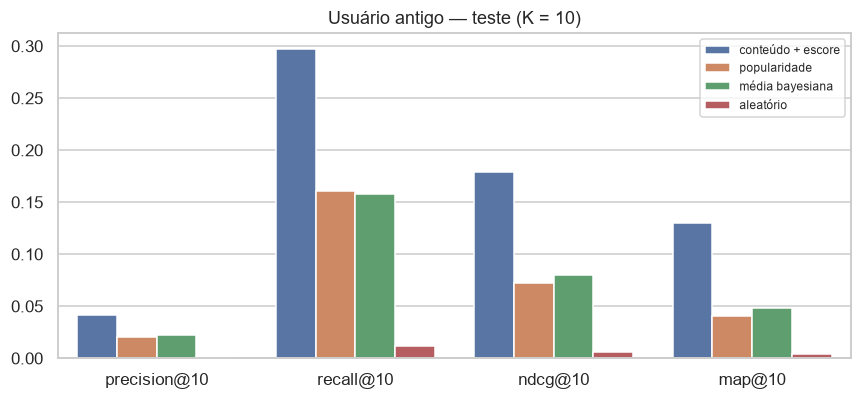

In [3]:
def bars(df, metrics, title, name):
    long = df.reset_index().melt(id_vars="modelo", value_vars=metrics, var_name="métrica", value_name="valor")
    fig, ax = plt.subplots(figsize=(8, 3.8))
    sns.barplot(data=long, x="métrica", y="valor", hue="modelo", ax=ax)
    ax.set(title=title, xlabel="", ylabel="")
    ax.legend(fontsize=8)
    save(fig, name)

bars(warm, ["precision@10", "recall@10", "ndcg@10", "map@10"], "Usuário antigo — teste (K = 10)", "aval_usuario_antigo")
ours, pop = warm.loc["conteúdo + escore"], warm.loc["popularidade"]
print(f"NDCG@10: {ours['ndcg@10'] / pop['ndcg@10'] - 1:+.1%} sobre popularidade; "
      f"cobertura {ours['cobertura']:.1%} vs {pop['cobertura']:.1%}")

## 2. Usuário novo
O usuário informa suas primeiras *n* notas (no app: ou escolhe tipos, uvas e pratos no onboarding). Os baselines não usam nenhuma informação do usuário.

In [4]:
cold_u = eval_cold_users(model, splits["cold_users"])
cold_u[["modelo", "n_notas_informadas", "precision@10", "recall@10", "ndcg@10", "map@10", "hit@10", "n_avaliados"]].round(4)

,modelo,n_notas_informadas,precision@10,recall@10,ndcg@10,map@10,hit@10,n_avaliados
0,conteúdo + escore,1,0.0550,0.1768,0.1213,0.0712,0.3865,802
1,conteúdo + escore,3,0.0632,0.2062,0.1417,0.0844,0.4314,802
2,conteúdo + escore,5,0.0688,0.2221,0.1519,0.0904,0.4663,802
3,conteúdo + escore,10,0.0758,0.2399,0.1709,0.1057,0.4838,802
4,popularidade,0,0.0322,0.1232,0.0654,0.0311,0.2656,802
5,média bayesiana,0,0.0431,0.1287,0.0881,0.0466,0.3055,802
6,aleatório,0,0.0034,0.0124,0.0080,0.0045,0.0337,802


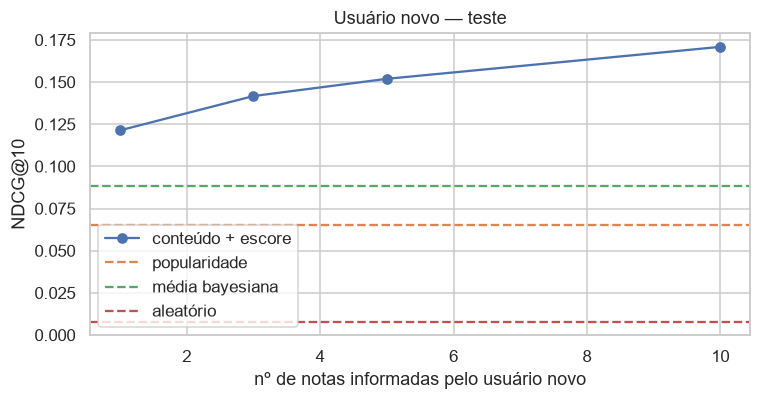

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.8))
cm = cold_u[cold_u["modelo"] == "conteúdo + escore"]
ax.plot(cm["n_notas_informadas"], cm["ndcg@10"], marker="o", label="conteúdo + escore")
for (_, r), c in zip(cold_u[cold_u["modelo"] != "conteúdo + escore"].iterrows(), ["C1", "C2", "C3"]):
    ax.axhline(r["ndcg@10"], ls="--", c=c, label=r["modelo"])
ax.set(xlabel="nº de notas informadas pelo usuário novo", ylabel="NDCG@10", title="Usuário novo — teste")
ax.legend()
save(fig, "aval_usuario_novo")

## 3. Vinho novo

Vinhos sem nenhuma nota no treino, só com atributos.
- **usuário → vinhos novos**: para cada usuário antigo, ordenar apenas os vinhos novos (popularidade não existe para eles, então o baseline é aleatório);
- **vinho novo → usuários**: para cada vinho novo, escolher a quem mostrá-lo. Baseline: os usuários mais ativos. Como cada vinho novo tem poucos fãs entre milhares de usuários, o top-10 quase nunca acerta; a métrica principal aqui é a **AUC** (probabilidade de um fã ficar acima de um não fã).

In [6]:
cold_items = items[items["item_id"].isin(splits["cold_item_ids"])]
cold_i = eval_cold_items(model, cold_items, splits["cold_items_test"])
cold_i[["visão", "modelo", "auc", "precision@10", "recall@10", "ndcg@10", "map@10", "hit@10", "n_avaliados"]].round(4)

,visão,modelo,auc,precision@10,recall@10,ndcg@10,map@10,hit@10,n_avaliados
0,usuário → vinhos novos,conteúdo,NaN,0.0505,0.4903,0.3289,0.2767,0.5049,103
1,usuário → vinhos novos,aleatório,NaN,0.0204,0.2039,0.0960,0.0645,0.2039,103
2,vinho novo → usuários,conteúdo,0.7818,0.0074,0.0395,0.0257,0.0189,0.0741,27
3,vinho novo → usuários,usuários mais ativos,0.4656,0.0000,0.0000,0.0000,0.0000,0.0000,27
4,vinho novo → usuários,aleatório,0.5014,0.0000,0.0000,0.0000,0.0000,0.0000,27


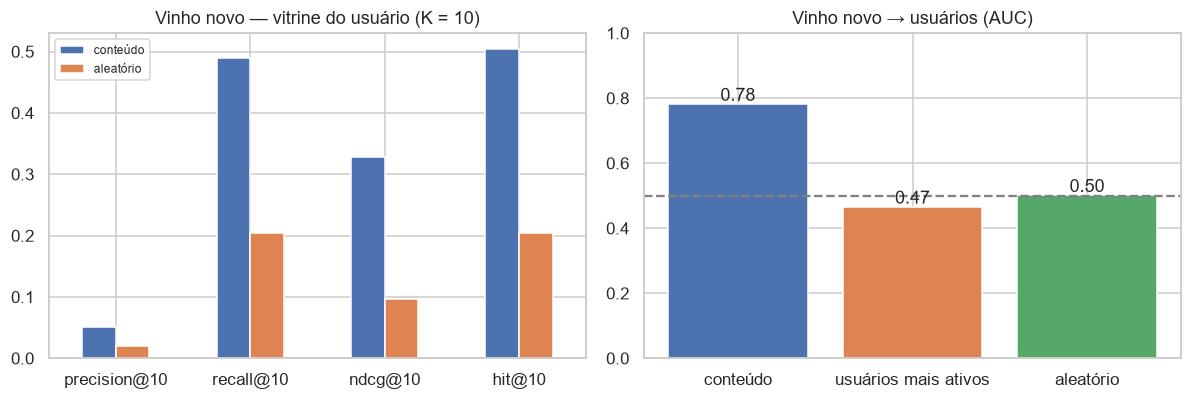

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
d = cold_i[cold_i["visão"] == "usuário → vinhos novos"].set_index("modelo")[["precision@10", "recall@10", "ndcg@10", "hit@10"]]
d.T.plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Vinho novo — vitrine do usuário (K = 10)", ylabel="")
axes[0].legend(fontsize=8)
d = cold_i[cold_i["visão"] == "vinho novo → usuários"].set_index("modelo")["auc"]
axes[1].bar(d.index, d.values, color=["C0", "C1", "C2"][:len(d)])
axes[1].axhline(0.5, ls="--", c="gray")
for x, v in enumerate(d.values):
    axes[1].text(x, v + 0.01, f"{v:.2f}", ha="center")
axes[1].set(title="Vinho novo → usuários (AUC)", ylim=(0, 1))
save(fig, "aval_item_novo")

## 4. Resumo para o slide

In [8]:
def best_baseline(df, col="modelo", ours=("conteúdo + escore", "conteúdo")):
    b = df[~df[col].isin(ours)].sort_values("ndcg@10").iloc[-1]
    return b[col], b["ndcg@10"]

rows = [("usuário antigo", warm.loc["conteúdo + escore", "ndcg@10"], *best_baseline(warm.reset_index())),
        ("usuário novo (5 notas)", cm.loc[cm["n_notas_informadas"] == 5, "ndcg@10"].iloc[0], *best_baseline(cold_u))]
d = cold_i[cold_i["visão"] == "usuário → vinhos novos"]
rows.append(("vinho novo: vitrine do usuário", d.loc[d["modelo"] == "conteúdo", "ndcg@10"].iloc[0], *best_baseline(d)))
summary = pd.DataFrame(rows, columns=["cenário", "modelo", "melhor baseline", "baseline"])
summary["métrica"] = "NDCG@10"
d = cold_i[cold_i["visão"] == "vinho novo → usuários"]
b = d[d["modelo"] != "conteúdo"].sort_values("auc").iloc[-1]
summary.loc[len(summary)] = ["vinho novo → usuários", d.loc[d["modelo"] == "conteúdo", "auc"].iloc[0],
                             b["modelo"], b["auc"], "AUC"]
summary["ganho"] = [f"{m / b - 1:+.0%}" if b > 0 else "baseline = 0" for m, b in zip(summary["modelo"], summary["baseline"])]
summary.round(4)

,cenário,modelo,melhor baseline,baseline,métrica,ganho
0,usuário antigo,0.1785,média bayesiana,0.0797,NDCG@10,+124%
1,usuário novo (5 notas),0.1519,média bayesiana,0.0881,NDCG@10,+72%
2,vinho novo: vitrine do usuário,0.3289,aleatório,0.0960,NDCG@10,+243%
3,vinho novo → usuários,0.7818,aleatório,0.5014,AUC,+56%


## 5. Robustez

- **Sementes**: o sorteio dos usuários novos muda com a semente (o split temporal e os vinhos novos são determinísticos);
- **Limiar de relevância**: 4,5 (principal) e 4,0 (a nota típica da base);
- **Intervalos de confiança**: bootstrap pareado por usuário, 2.000 reamostragens.

In [9]:
from src.evaluate import confidence_intervals, robustness

rob = robustness(featurizer, params, ratings, items)
rob_sum = rob.groupby(["limiar", "cenário"])[["modelo", "melhor baseline"]].agg(["mean", "std"]).round(4)
rob_sum

modelo         melhor baseline        
                                         mean     std            mean     std
limiar cenário                                                               
4.0    usuário antigo                  0.1013  0.0011          0.0589  0.0008
       usuário novo (5 notas)          0.1066  0.0041          0.0636  0.0011
       vinho novo → usuários (AUC)     0.7246  0.0100          0.4991  0.0054
       vinho novo: vitrine do usuário  0.2492  0.0041          0.0964  0.0072
4.5    usuário antigo                  0.1786  0.0021          0.0805  0.0014
       usuário novo (5 notas)          0.1544  0.0046          0.0880  0.0025
       vinho novo → usuários (AUC)     0.7874  0.0040          0.5008  0.0146
       vinho novo: vitrine do usuário  0.3190  0.0077          0.1040  0.0163

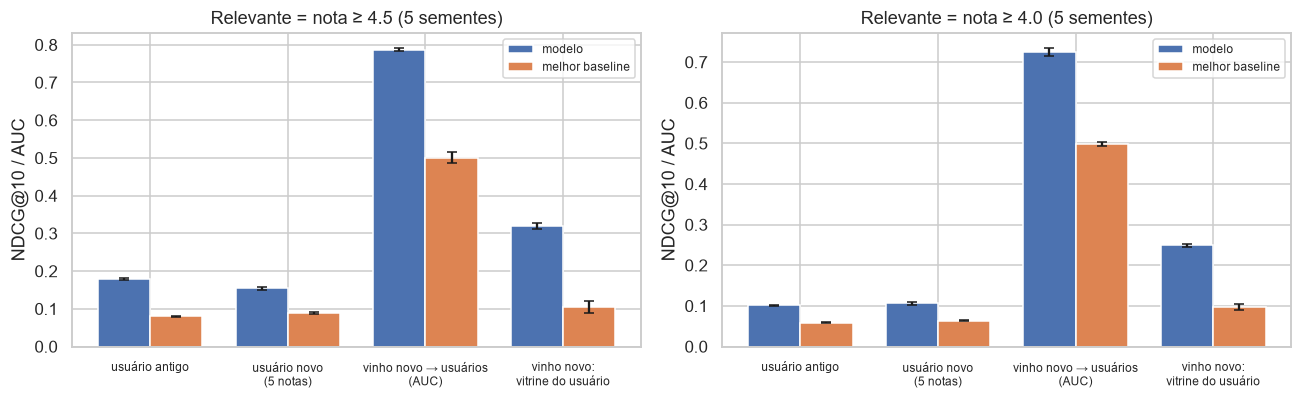

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, thr in zip(axes, [4.5, 4.0]):
    d = rob[rob["limiar"] == thr].groupby("cenário")[["modelo", "melhor baseline"]].agg(["mean", "std"])
    x = np.arange(len(d))
    for j, (col, c) in enumerate([("modelo", "C0"), ("melhor baseline", "C1")]):
        ax.bar(x + (j - 0.5) * 0.38, d[(col, "mean")], 0.38, yerr=d[(col, "std")], color=c, label=col, capsize=3)
    ax.set_xticks(x, [c.replace(": ", ":\n").replace(" (", "\n(") for c in d.index], fontsize=8)
    ax.set(title=f"Relevante = nota ≥ {thr} (5 sementes)", ylabel="NDCG@10 / AUC")
    ax.legend(fontsize=8)
save(fig, "robustez")

In [11]:
ci = confidence_intervals(model, splits, cold_items)
ci_fmt = ci.assign(**{"ganho (IC 95%)": [f"{lo:+.0%} a {hi:+.0%}" for lo, hi in zip(ci["ganho_ic_inf"], ci["ganho_ic_sup"])]})
ci_fmt[["cenário", "baseline", "modelo", "ganho (IC 95%)", "n"]].round(4)

,cenário,baseline,modelo,ganho (IC 95%),n
0,usuário antigo,0.0797,0.1785,+111% a +137%,4307
1,usuário novo (5 notas),0.0881,0.1519,+56% a +91%,802
2,vinho novo: vitrine do usuário,0.0965,0.3289,+162% a +322%,103


## 6. Exemplos dos três cenários

In [12]:
u = splits["test"]["user_id"].value_counts().index[0]
print(f"Usuário antigo {u} — histórico (melhores notas):")
display(model.user_history(u, splits["train"], 5))
model.recommend_existing_user(u, 10)[["name", "winery", "type", "country", "grapes", "score", "porque"]].round(3)

Usuário antigo 1006657 — histórico (melhores notas):


,item_id,name,type,country,grapes,rating,date
25,113193,Listrac-Médoc,Red,France,"[Cabernet Sauvignon, Cabernet Franc, Merlot]",5.0,2017-04-08 15:40:12
39,111457,Châteauneuf-du-Pape,Red,France,[Syrah/Shiraz],4.5,2017-11-20 16:40:30
37,111713,Corton-Charlemagne Grand Cru,White,France,[Chardonnay],4.5,2017-11-16 16:17:38
32,112511,Pomerol,Red,France,[Merlot],4.5,2017-06-06 12:40:49
20,111521,Grand Vintage Brut Champagne,Sparkling,France,[Chardonnay],4.5,2017-01-18 09:17:17


,name,winery,type,country,grapes,score,porque
0,Pauillac (Premier Grand Cru Classé),Château Mouton Rothschild,Red,France,"[Cabernet Sauvignon, Cabernet Franc, Merlot, Petit Verdot]",0.827,"país France, tipo Red, corpo Full-bodied, acidez High"
1,Cabernet Sauvignon,Don Melchor,Red,Chile,[Cabernet Sauvignon],0.803,"uva Cabernet Sauvignon, tipo Red, corpo Full-bodied, aci..."
2,Pauillac (Premier Grand Cru Classé),Château Lafite Rothschild,Red,France,"[Merlot, Cabernet Sauvignon]",0.798,"país France, uva Cabernet Sauvignon, uva Merlot, tipo Red"
3,Pauillac (Grand Cru Classé),Château Pichon Longueville Comtesse de Lalande,Red,France,"[Cabernet Sauvignon, Merlot, Cabernet Franc, Petit Verdot]",0.780,"país France, tipo Red, corpo Full-bodied, acidez High"
4,Pauillac (Grand Cru Classé),Château Pichon Baron,Red,France,"[Merlot, Cabernet Sauvignon]",0.780,"país France, uva Cabernet Sauvignon, uva Merlot, tipo Red"
5,Saint-Estèphe (Grand Cru Classé),Château Montrose,Red,France,"[Cabernet Sauvignon, Cabernet Franc, Merlot]",0.761,"país France, tipo Red, corpo Full-bodied, elaboração Ass..."
6,Saint-Julien (Grand Cru Classé),Château Léoville Poyferré,Red,France,"[Cabernet Sauvignon, Merlot, Cabernet Franc, Petit Verdot]",0.750,"país France, tipo Red, corpo Full-bodied, acidez High"
7,Grange,Penfolds,Red,Australia,[Syrah/Shiraz],0.746,"tipo Red, acidez High, corpo Very full-bodied, elaboraçã..."
8,Insignia,Joseph Phelps,Red,United States,[Pinot Noir],0.745,"tipo Red, corpo Full-bodied, elaboração Varietal/100%, u..."
9,Rioja Gran Reserva 904,La Rioja Alta,Red,Spain,[Tempranillo],0.740,"tipo Red, corpo Full-bodied, acidez High, elaboração Var..."


In [13]:
print("Usuário novo: tintos encorpados, Malbec/Cabernet, para carne e churrasco; até 14,5% de álcool")
prefs = {"types": ["Red"], "grapes": ["Malbec", "Cabernet Sauvignon"], "harmonize": ["Beef", "Grilled"],
         "body": ["Full-bodied"]}
model.recommend_new_user(prefs, k=10, types=["Red"], max_abv=14.5)[["name", "winery", "country", "grapes", "abv", "porque"]]

Usuário novo: tintos encorpados, Malbec/Cabernet, para carne e churrasco; até 14,5% de álcool


,name,winery,country,grapes,abv,porque
0,Cabernet Sauvignon,Don Melchor,Chile,[Cabernet Sauvignon],14.5,"uva Cabernet Sauvignon, corpo Full-bodied, tipo Red, com..."
1,Pauillac (Grand Cru Classé),Château Duhart-Milon,France,[Cabernet Sauvignon],12.5,"uva Cabernet Sauvignon, corpo Full-bodied, tipo Red, com..."
2,Cabernet Sauvignon,Jordan,United States,[Cabernet Sauvignon],13.8,"uva Cabernet Sauvignon, corpo Full-bodied, tipo Red, com..."
3,Rouge (Gaston Hochar),Château Musar,Lebanon,[Cabernet Sauvignon],14.0,"uva Cabernet Sauvignon, corpo Full-bodied, tipo Red, com..."
4,Cocodrilo Red Blend,Viña Cobos,Argentina,"[Cabernet Sauvignon, Malbec, Petit Verdot, Merlot]",14.5,"uva Malbec, corpo Full-bodied, tipo Red, uva Cabernet Sa..."
5,ARTEMIS Cabernet Sauvignon,Stag's Leap Wine Cellars,United States,[Cabernet Sauvignon],14.5,"uva Cabernet Sauvignon, corpo Full-bodied, tipo Red, com..."
6,Rubicon,Meerlust,South Africa,[Cabernet Sauvignon],14.4,"uva Cabernet Sauvignon, corpo Full-bodied, tipo Red, com..."
7,Knights Valley Cabernet Sauvignon,Beringer,United States,[Cabernet Sauvignon],14.5,"uva Cabernet Sauvignon, corpo Full-bodied, tipo Red, com..."
8,Montes Alpha Cabernet Sauvignon,Montes,Chile,[Cabernet Sauvignon],14.0,"uva Cabernet Sauvignon, corpo Full-bodied, tipo Red, com..."
9,Classic Cabernet Sauvignon,Barkan,Israel,[Cabernet Sauvignon],13.2,"uva Cabernet Sauvignon, corpo Full-bodied, tipo Red, com..."


In [14]:
print("Usuário novo sem nenhuma informação → ranking pelo escore de produto")
model.recommend_new_user(k=5)[["name", "type", "country", "nota_bayesiana", "n_notas"]].round(2)

Usuário novo sem nenhuma informação → ranking pelo escore de produto


,name,type,country,nota_bayesiana,n_notas
0,Pauillac (Premier Grand Cru Classé),Red,France,4.68,733
1,Cabernet Sauvignon,Red,Chile,4.64,774
2,Grange,Red,Australia,4.73,427
3,Pauillac (Premier Grand Cru Classé),Red,France,4.68,484
4,Special Selection Cabernet Sauvignon,Red,United States,4.64,515


In [15]:
novo = pd.DataFrame([{
    "item_id": 999_001, "name": "Tannat Reserva (novo no catálogo)", "type": "Red", "elaborate": "Varietal/100%",
    "grapes": ["Tannat"], "harmonize": ["Beef", "Lamb", "Grilled", "Maturated Cheese"], "abv": 14.0,
    "body": "Full-bodied", "acidity": "High", "country": "Uruguay", "region": "Canelones",
    "winery": "Vinícola Exemplo", "vintages": ["2022"], "n_grapes": 1, "n_vintages": 1,
}])
model.add_items(novo)
print("Vinho recém-cadastrado:", novo["name"].iloc[0], "→ usuários antigos com maior afinidade:")
fans = model.recommend_new_item(999_001, 10)
fans.round(3)

Vinho recém-cadastrado: Tannat Reserva (novo no catálogo) → usuários antigos com maior afinidade:


,user_id,afinidade,similaridade,porque
0,1147079,0.502,0.502,"tipo Red, uva Tannat, corpo Full-bodied, região Canelones"
1,1225601,0.500,0.500,"uva Tannat, país Uruguay, tipo Red, região Canelones"
2,1357753,0.490,0.490,"corpo Full-bodied, tipo Red, uva Tannat, elaboração Vari..."
3,1248247,0.476,0.476,"país Uruguay, uva Tannat, tipo Red, corpo Full-bodied"
4,1387838,0.466,0.466,"corpo Full-bodied, uva Tannat, tipo Red, elaboração Vari..."
5,1223410,0.456,0.456,"uva Tannat, país Uruguay, corpo Full-bodied, tipo Red"
6,1400767,0.445,0.445,"uva Tannat, país Uruguay, corpo Full-bodied, tipo Red"
7,1405443,0.439,0.439,"tipo Red, corpo Full-bodied, acidez High, elaboração Var..."
8,1194786,0.438,0.438,"região Canelones, tipo Red, uva Tannat, país Uruguay"
9,1250026,0.438,0.438,"região Canelones, tipo Red, uva Tannat, acidez High"


In [16]:
model.add_items(cold_items)  # vinhos novos do teste, sem nenhuma nota no treino
u_fan = fans["user_id"].iloc[0]
print(f"Vitrine de novidades do usuário {u_fan} (só vinhos sem nenhuma nota):")
model.recommend_new_items_for_user(u_fan, 5)[["name", "winery", "type", "country", "grapes", "similaridade", "porque"]].round(3)

Vitrine de novidades do usuário 1147079 (só vinhos sem nenhuma nota):


,name,winery,type,country,grapes,similaridade,porque
0,Tannat Reserva (novo no catálogo),Vinícola Exemplo,Red,Uruguay,[Tannat],0.502,"tipo Red, uva Tannat, corpo Full-bodied, região Canelones"
1,Reserve Cabernet Sauvignon,Golubitskoe Estate-Villa Romanov,Red,Russia,[Cabernet Sauvignon],0.421,"tipo Red, uva Cabernet Sauvignon, corpo Full-bodied, aci..."
2,Four Sons Fraternity,Baldacci,Red,United States,"[Cabernet Sauvignon, Cabernet Franc, Pinotage, Syrah/Shi...",0.384,"tipo Red, corpo Full-bodied, elaboração Assemblage/Blend..."
3,Susumaniello,Li Veli,Red,Italy,[Susumaniello],0.355,"tipo Red, corpo Full-bodied, acidez High, elaboração Var..."
4,Merlot,Parkers Estate,Red,United States,[Merlot],0.353,"tipo Red, corpo Full-bodied, acidez High, elaboração Var..."


## 7. Modelo final para a interface
Retreinado com **todas** as notas do k-core (treino + teste + usuários/vinhos separados) e salvo para o app.

In [17]:
final = ContentRecommender(featurizer, **model_params)
kcore_items = items[items["item_id"].isin(ratings["item_id"].unique())]
final.fit(ratings, kcore_items)
models_dir = ROOT / "models"
models_dir.mkdir(exist_ok=True)
with open(models_dir / "recommender.pkl", "wb") as f:
    pickle.dump(final, f)
print(f"{len(final.user_ids):,} usuários, {len(final.item_ids):,} vinhos, "
      f"{(models_dir / 'recommender.pkl').stat().st_size / 1e6:.1f} MB")

10,252 usuários, 924 vinhos, 10.7 MB
